In [1]:
from datasets import load_dataset
dataset = load_dataset("ailsntua/QEvasion")


c:\Users\AkselDindisyan\Desktop\4.1Senior\CS445\Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label'],
        num_rows: 3448
    })
    test: Dataset({
        features: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label'],
        num_rows: 308
    })
})


In [5]:
# Convert Hugging Face Dataset/DatasetDict to separate train and test DataFrames
from datasets import DatasetDict, Dataset

if isinstance(dataset, DatasetDict):
    # Extract train and test splits
    df_train = dataset['train'].to_pandas() if 'train' in dataset else None
    df_test = dataset['test'].to_pandas() if 'test' in dataset else None
    
    if df_train is None or df_test is None:
        raise ValueError(f"Dataset must contain 'train' and 'test' splits. Available splits: {list(dataset.keys())}")
    
    print(f"Train DataFrame shape: {df_train.shape}")
    print(f"Test DataFrame shape: {df_test.shape}")
elif isinstance(dataset, Dataset):
    raise ValueError("Dataset is a single Dataset, not DatasetDict. Cannot split into train and test.")
else:
    raise ValueError("Unable to process dataset")

# Show a quick preview
print("\nTrain DataFrame preview:")
print(df_train.head())
print("\nTest DataFrame preview:")
print(df_test.head())

Train DataFrame shape: (3448, 20)
Test DataFrame shape: (308, 20)

Train DataFrame preview:
                                               title                date  \
0  The President's News Conference in Hanoi, Vietnam  September 10, 2023   
1  The President's News Conference in Hanoi, Vietnam  September 10, 2023   
2  The President's News Conference in Hanoi, Vietnam  September 10, 2023   
3  The President's News Conference in Hanoi, Vietnam  September 10, 2023   
4  The President's News Conference in Hanoi, Vietnam  September 10, 2023   

         president                                                url  \
0  Joseph R. Biden  https://www.presidency.ucsb.edu/documents/the-...   
1  Joseph R. Biden  https://www.presidency.ucsb.edu/documents/the-...   
2  Joseph R. Biden  https://www.presidency.ucsb.edu/documents/the-...   
3  Joseph R. Biden  https://www.presidency.ucsb.edu/documents/the-...   
4  Joseph R. Biden  https://www.presidency.ucsb.edu/documents/the-...   

   question_

## Explatory Data Analysis(EDA)

In [6]:
df_train.head(5)

,title,date,president,url,question_order,interview_question,interview_answer,gpt3.5_summary,gpt3.5_prediction,question,annotator_id,annotator1,annotator2,annotator3,inaudible,multiple_questions,affirmative_questions,index,clarity_label,evasion_label
0,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,How would you respond to the accusation that t...,85,None,None,None,False,False,False,0,Clear Reply,Explicit
1,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,Do you think President Xi is being sincere abo...,85,None,None,None,False,False,False,1,Ambivalent,General
2,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,2,Q. No worries. Do you believe the country's sl...,"Look, I think China has a difficult economic p...",The question consists of two parts:\n\n1. Q1: ...,Question part: Q1 - Do you believe the country...,Do you believe the country's slowdown and gro...,85,None,None,None,False,False,False,2,Ambivalent,Partial/half-answer
3,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,2,Q. No worries. Do you believe the country's sl...,"Look, I think China has a difficult economic p...",The question consists of two parts:\n\n1. Q1: ...,Question part: Q1 - Do you believe the country...,Are you worried about the meeting between Pre...,85,None,None,None,False,False,False,3,Ambivalent,Dodging
4,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,3,"Q. I can imagine. It is evening, I'd like to r...","Well, I hope I get to see Mr. Xi sooner than l...",The question consists of 3 parts:\n1. Is the P...,Question part: 1. Is the President's engagemen...,Is the President's engagement with Asian coun...,85,None,None,None,False,False,False,4,Clear Reply,Explicit


In [7]:
#There are three null columns which are annotator1, annotator2, annotator3
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3448 entries, 0 to 3447
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   title                  3448 non-null   object
 1   date                   3448 non-null   object
 2   president              3448 non-null   object
 3   url                    3448 non-null   object
 4   question_order         3448 non-null   int64 
 5   interview_question     3448 non-null   object
 6   interview_answer       3448 non-null   object
 7   gpt3.5_summary         3448 non-null   object
 8   gpt3.5_prediction      3448 non-null   object
 9   question               3448 non-null   object
 10  annotator_id           3448 non-null   object
 11  annotator1             0 non-null      object
 12  annotator2             0 non-null      object
 13  annotator3             0 non-null      object
 14  inaudible              3448 non-null   bool  
 15  multiple_questions   

In [8]:
#Drop null columns
df_train = df_train.drop(["annotator1","annotator2","annotator3"], axis=1)


In [9]:
df_train.head(5)

,title,date,president,url,question_order,interview_question,interview_answer,gpt3.5_summary,gpt3.5_prediction,question,annotator_id,inaudible,multiple_questions,affirmative_questions,index,clarity_label,evasion_label
0,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,How would you respond to the accusation that t...,85,False,False,False,0,Clear Reply,Explicit
1,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,Do you think President Xi is being sincere abo...,85,False,False,False,1,Ambivalent,General
2,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,2,Q. No worries. Do you believe the country's sl...,"Look, I think China has a difficult economic p...",The question consists of two parts:\n\n1. Q1: ...,Question part: Q1 - Do you believe the country...,Do you believe the country's slowdown and gro...,85,False,False,False,2,Ambivalent,Partial/half-answer
3,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,2,Q. No worries. Do you believe the country's sl...,"Look, I think China has a difficult economic p...",The question consists of two parts:\n\n1. Q1: ...,Question part: Q1 - Do you believe the country...,Are you worried about the meeting between Pre...,85,False,False,False,3,Ambivalent,Dodging
4,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,3,"Q. I can imagine. It is evening, I'd like to r...","Well, I hope I get to see Mr. Xi sooner than l...",The question consists of 3 parts:\n1. Is the P...,Question part: 1. Is the President's engagemen...,Is the President's engagement with Asian coun...,85,False,False,False,4,Clear Reply,Explicit


<Axes: ylabel='president'>

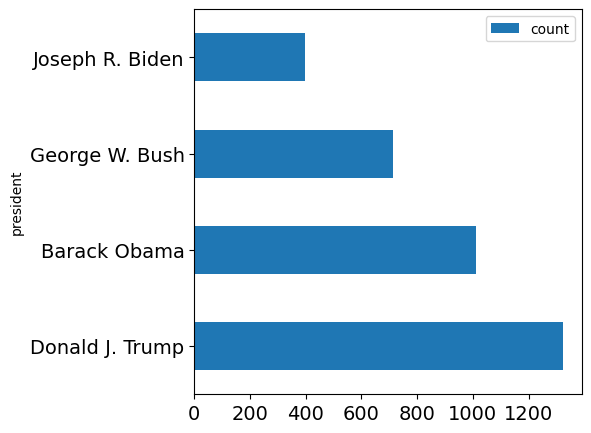

In [ ]:
#Occurance of each person
president_occurence = df_train["president"].value_counts()
president_occurence.plot(kind="barh",legend=True,figsize=(5,5),fontsize=14,title= "President Occurance")


<Axes: title={'center': 'Clarity Label Distribution'}, ylabel='clarity_label'>

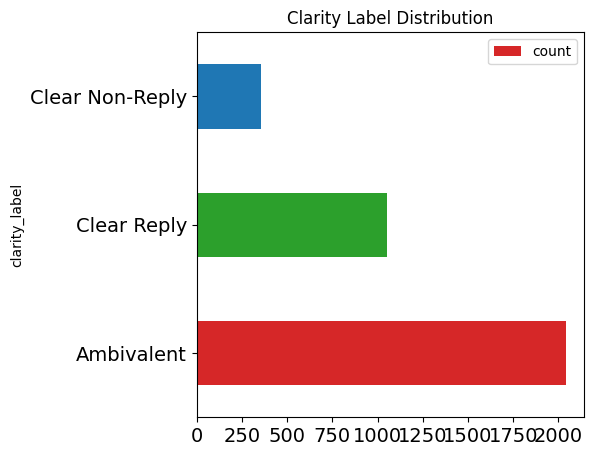

In [37]:
president_occurence = df_train["clarity_label"].value_counts()
president_occurence.plot(kind="barh",legend=True,figsize=(5,5),fontsize=14,title="Clarity Label Distribution",color=["tab:red","tab:green","tab:blue"])

<Axes: title={'center': 'Evasion Label Distribution'}, ylabel='evasion_label'>

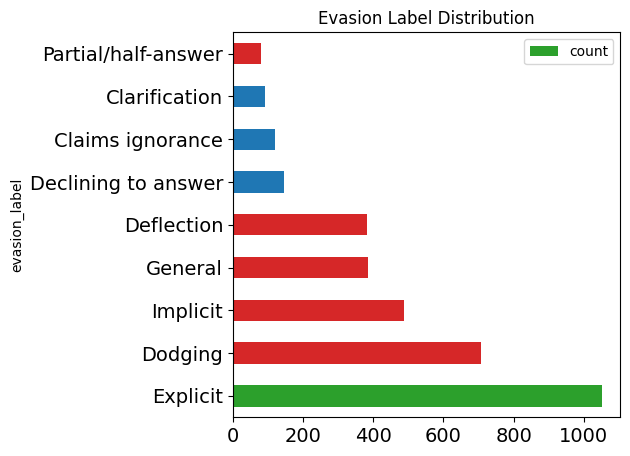

In [38]:
president_occurence = df_train["evasion_label"].value_counts()
bar_colors = ['tab:green',"tab:red","tab:red","tab:red","tab:red","tab:blue","tab:blue","tab:blue","tab:red"]
president_occurence.plot(kind="barh",legend=True,figsize=(5,5),fontsize=14,title="Evasion Label Distribution",color=bar_colors)